In [10]:
# import libraries
import requests
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from collections import deque, Counter
from urllib.parse import quote
import re
import time

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
# Configure the crawler

API_URL = "https://en.wikipedia.org/w/api.php"

SEED_ARTICLE = "Artificial intelligence"
MAX_PAGES = 30
REQUEST_DELAY = 1

HEADERS = {
    "User-Agent": (
        "StudentDWMWebCrawler/1.0 "
        "(educational project)"
    )
}

session = requests.Session()
session.headers.update(HEADERS)

print("Seed article:", SEED_ARTICLE)
print("Maximum pages:", MAX_PAGES)
print("Crawl method: Breadth-First Search (BFS)")

Seed article: Artificial intelligence
Maximum pages: 30
Crawl method: Breadth-First Search (BFS)


In [12]:
# Creating the API extraction function
def fetch_article(title):
    params = {
        "action": "query",
        "format": "json",
        "prop": "extracts|links",
        "explaintext": 1,
        "plnamespace": 0,
        "pllimit": "max",
        "titles": title,
        "redirects": 1
    }

    response = session.get(
        API_URL,
        params=params,
        timeout=20
    )

    response.raise_for_status()
    data = response.json()

    if "error" in data:
        raise RuntimeError(data["error"])

    page = next(
        iter(data["query"]["pages"].values())
    )

    if "missing" in page:
        return None

    links = [
        item["title"]
        for item in page.get("links", [])
    ]

    return {
        "title": page["title"],
        "page_id": page["pageid"],
        "text": page.get("extract", ""),
        "links": links
    }

In [13]:
# Test extraction

article = fetch_article(SEED_ARTICLE)

if article:
    print("Article:", article["title"])
    print("Page ID:", article["page_id"])
    print("Text length:", len(article["text"]))
    print("Outgoing links:", len(article["links"]))

    print("\nText preview:")
    print(article["text"][:500])

    print("\nFirst 15 outgoing links:")
    print(article["links"][:15])
else:
    print("Article could not be found.")

Article: Artificial intelligence
Page ID: 1164
Text length: 87602
Outgoing links: 500

Text preview:
Artificial intelligence (AI) is the capability of computational systems to perform tasks typically associated with human intelligence, such as learning, reasoning, problem-solving, perception, and decision-making. It is a field of research in engineering, mathematics, and computer science that develops and studies methods and software that enable machines to perceive their environment and use learning and intelligence to take actions that maximise their chances of achieving defined goals.
High-p

First 15 outgoing links:
['15.ai', '1X Technologies', '2001: A Space Odyssey', '2001: A Space Odyssey (novel)', '2024 Indian general election', '2026 cyberattacks by rogue OpenAI agents', '3D optical data storage', 'A* search algorithm', 'A.I. Artificial Intelligence', 'AAAI', 'ABB', 'ACM Computing Classification System', 'ACM Conference on Fairness, Accountability, and Transparency', 'ACM SIGE

In [16]:
# Script 5: Configure safe requests and automatic retries.
# Retries temporary errors, respects Retry-After when provided,
# and uses a descriptive User-Agent.

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

session = requests.Session()

HEADERS = {
    "User-Agent": (
        "DWMStudentCrawler/1.0 "
        "(educational project; aosstriffmousepad@gmail.com)"
    )
}
session.headers.update(HEADERS)

retry_policy = Retry(
    total=4,
    connect=3,
    read=3,
    status=4,
    backoff_factor=5,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
    respect_retry_after_header=True
)

adapter = HTTPAdapter(max_retries=retry_policy)
session.mount("https://", adapter)
session.mount("http://", adapter)

print("Session configured with retry and backoff.")

Session configured with retry and backoff.


In [17]:
# Script 6: Fetch one Wikipedia article.
# Returns None for missing articles and raises request errors
# when retries are exhausted.

def fetch_article(title):
    params = {
        "action": "query",
        "format": "json",
        "prop": "extracts|links",
        "explaintext": 1,
        "plnamespace": 0,
        "pllimit": "max",
        "titles": title,
        "redirects": 1
    }

    response = session.get(
        API_URL,
        params=params,
        timeout=30
    )
    response.raise_for_status()

    data = response.json()

    if "error" in data:
        raise RuntimeError(data["error"])

    page = next(iter(data["query"]["pages"].values()))

    if "missing" in page:
        return None

    return {
        "title": page["title"],
        "page_id": page["pageid"],
        "text": page.get("extract", ""),
        "links": [
            link["title"]
            for link in page.get("links", [])
        ]
    }

print("Article-fetching function updated.")

Article-fetching function updated.


In [18]:
# Script 7: Test the API with one request.
# Do not start the full crawl unless this test succeeds.

try:
    test_article = fetch_article(SEED_ARTICLE)

    if test_article:
        print("API test successful!")
        print("Title:", test_article["title"])
        print("Text length:", len(test_article["text"]))
        print("Outgoing links:", len(test_article["links"]))
    else:
        print("The article was not found.")

except requests.RequestException as error:
    print("API request failed:", error)
    print("Do not start the full crawl yet.")

API test successful!
Title: Artificial intelligence
Text length: 87602
Outgoing links: 500


In [19]:
# Script 8: BFS crawler with successful-page counting.
# Failed requests do not count toward the 30 successful pages.
# A failed title is not retried indefinitely by the crawler.

queue = deque([SEED_ARTICLE])
queued = {SEED_ARTICLE}
successful_titles = set()
failed_titles = set()

pages_data = []
links_data = []

MAX_ATTEMPTS = MAX_PAGES * 2
attempts = 0

while queue and len(pages_data) < MAX_PAGES and attempts < MAX_ATTEMPTS:
    title = queue.popleft()

    if title in successful_titles or title in failed_titles:
        continue

    attempts += 1
    print(
        f"Attempt {attempts}/{MAX_ATTEMPTS} | "
        f"Successful pages: {len(pages_data)}/{MAX_PAGES} | "
        f"{title}"
    )

    try:
        article = fetch_article(title)

        if article is None:
            failed_titles.add(title)
            continue

        successful_titles.add(article["title"])

        pages_data.append({
            "title": article["title"],
            "page_id": article["page_id"],
            "text": article["text"],
            "text_length": len(article["text"]),
            "word_count": len(article["text"].split()),
            "outgoing_links": len(article["links"])
        })

        for linked_title in article["links"]:
            links_data.append({
                "source": article["title"],
                "target": linked_title
            })

            if (
                linked_title not in queued
                and linked_title not in successful_titles
                and linked_title not in failed_titles
                and len(successful_titles) + len(queue) < MAX_PAGES
            ):
                queue.append(linked_title)
                queued.add(linked_title)

    except requests.RequestException as error:
        failed_titles.add(title)
        print("Request failed after retries:", error)

        # Stop if the server is still rate-limiting us.
        if (
            isinstance(error, requests.HTTPError)
            and error.response is not None
            and error.response.status_code == 429
        ):
            print("Rate limit persists. Stopping the crawl.")
            break

    finally:
        time.sleep(REQUEST_DELAY)

pages_df = pd.DataFrame(pages_data)
links_df = pd.DataFrame(links_data)

print("\nCrawl summary")
print("Successfully collected:", len(pages_df))
print("Failed article titles:", len(failed_titles))
print("Link relationships collected:", len(links_df))
print("Remaining queue:", len(queue))

Attempt 1/60 | Successful pages: 0/30 | Artificial intelligence
Attempt 2/60 | Successful pages: 1/30 | 15.ai
Attempt 3/60 | Successful pages: 2/30 | 1X Technologies
Attempt 4/60 | Successful pages: 3/30 | 2001: A Space Odyssey
Attempt 5/60 | Successful pages: 4/30 | 2001: A Space Odyssey (novel)
Attempt 6/60 | Successful pages: 5/30 | 2024 Indian general election
Attempt 7/60 | Successful pages: 6/30 | 2026 cyberattacks by rogue OpenAI agents
Attempt 8/60 | Successful pages: 7/30 | 3D optical data storage
Attempt 9/60 | Successful pages: 8/30 | A* search algorithm
Attempt 10/60 | Successful pages: 9/30 | A.I. Artificial Intelligence
Attempt 11/60 | Successful pages: 10/30 | AAAI
Attempt 12/60 | Successful pages: 11/30 | ABB
Attempt 13/60 | Successful pages: 12/30 | ACM Computing Classification System
Attempt 14/60 | Successful pages: 13/30 | ACM Conference on Fairness, Accountability, and Transparency
Attempt 15/60 | Successful pages: 14/30 | ACM SIGEVO
Attempt 16/60 | Successful page

In [20]:
# Purpose: Check dataset size, columns, missing values, and duplicate articles.

print("Articles shape:", pages_df.shape)
print("Links shape:", links_df.shape)

print("\nArticle dataset:")
display(pages_df.head())

print("\nMissing values:")
print(pages_df.isnull().sum())

print("\nDuplicate article titles:", pages_df["title"].duplicated().sum())

Articles shape: (30, 6)
Links shape: (7220, 2)

Article dataset:


,title,page_id,text,text_length,word_count,outgoing_links
0,Artificial intelligence,1164,Artificial intelligence (AI) is the capability...,87602,13282,500
1,15.ai,78635504,"15.ai was a free, non-commercial web applicati...",31817,4771,500
2,1X Technologies,79656092,1X Technologies is a Norwegian-American roboti...,2928,455,261
3,2001: A Space Odyssey,23941708,2001: A Space Odyssey is a 1968 epic science f...,75760,12435,500
4,2001: A Space Odyssey (novel),1660387,2001: A Space Odyssey is a 1968 science fictio...,21025,3344,153



Missing values:
title             0
page_id           0
text              0
text_length       0
word_count        0
outgoing_links    0
dtype: int64

Duplicate article titles: 0


In [21]:
# Purpose: Remove duplicate records and invalid or empty article entries.

pages_df = pages_df.drop_duplicates(subset="title").copy()
pages_df = pages_df.dropna(subset=["title", "text"])
pages_df = pages_df[pages_df["text"].str.strip() != ""]

links_df = links_df.dropna(subset=["source", "target"])
links_df = links_df.drop_duplicates()

print("Clean articles:", len(pages_df))
print("Clean link relationships:", len(links_df))

Clean articles: 30
Clean link relationships: 7220


In [22]:
# Purpose: Summarize article word counts and identify the longest articles.

print(pages_df["word_count"].describe())

print("\nTop 10 longest articles:")
display(
    pages_df[["title", "word_count"]]
    .sort_values("word_count", ascending=False)
    .head(10)
)

count       30.000000
mean      2691.833333
std       3326.337388
min        134.000000
25%        608.250000
50%       1262.500000
75%       3886.250000
max      13282.000000
Name: word_count, dtype: float64

Top 10 longest articles:


,title,word_count
0,Artificial intelligence,13282
3,2001: A Space Odyssey,12435
5,2024 Indian general election,7948
1,15.ai,4771
11,ABB,4598
28,AI winter,4409
9,A.I. Artificial Intelligence,4261
8,A* search algorithm,4067
4,2001: A Space Odyssey (novel),3344
16,ACT-R,2824


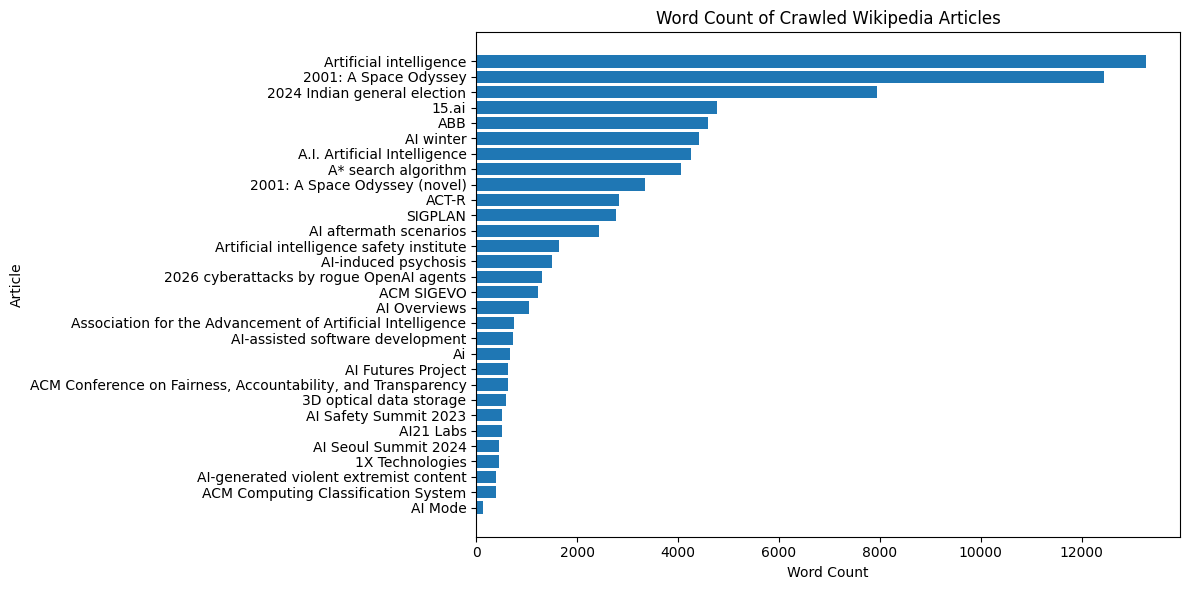

In [23]:
# Purpose: Visualize differences in the lengths of the collected articles.

import matplotlib.pyplot as plt

plot_df = pages_df.sort_values("word_count", ascending=False)

plt.figure(figsize=(12, 6))
plt.barh(plot_df["title"], plot_df["word_count"])
plt.xlabel("Word Count")
plt.ylabel("Article")
plt.title("Word Count of Crawled Wikipedia Articles")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [35]:
# Purpose: Convert article text into lowercase words and remove punctuation.

import re
from collections import Counter

def tokenize(text):
    return re.findall(r"\b[a-z]{2,}\b", text.lower())

pages_df["tokens"] = pages_df["text"].apply(tokenize)

print("Sample tokens:")
print(pages_df[["title", "tokens"]].head(3))

Sample tokens:
                     title                                             tokens
0  Artificial intelligence  [artificial, intelligence, ai, is, the, capabi...
1                    15.ai  [ai, was, free, non, commercial, web, applicat...
2          1X Technologies  [technologies, is, norwegian, american, roboti...


In [36]:
# Purpose: Identify frequently occurring words across all crawled articles.

stop_words = {
    "the", "and", "for", "that", "with", "from", "this", "are",
    "was", "were", "has", "have", "had", "its", "into", "their",
    "they", "not", "but", "also", "which", "who", "when", "where",
    "been", "being", "more", "most", "such", "than", "then",
    "can", "could", "would", "should", "about", "after", "before",
    "other", "some", "many", "each", "both", "only", "over",
    "under", "between", "using", "used", "use", "one", "two",
    "new", "all", "out", "you", "its", "his", "her", "our"
}

all_words = [
    word
    for tokens in pages_df["tokens"]
    for word in tokens
    if word not in stop_words
]

word_counts = Counter(all_words)

print("Top 20 frequent words:")
print(word_counts.most_common(20))

Top 20 frequent words:
[('of', 2527), ('in', 1882), ('to', 1818), ('ai', 796), ('by', 683), ('as', 637), ('on', 623), ('is', 621), ('it', 492), ('an', 332), ('film', 328), ('at', 312), ('be', 290), ('or', 256), ('kubrick', 190), ('intelligence', 180), ('artificial', 156), ('abb', 156), ('he', 149), ('human', 132)]


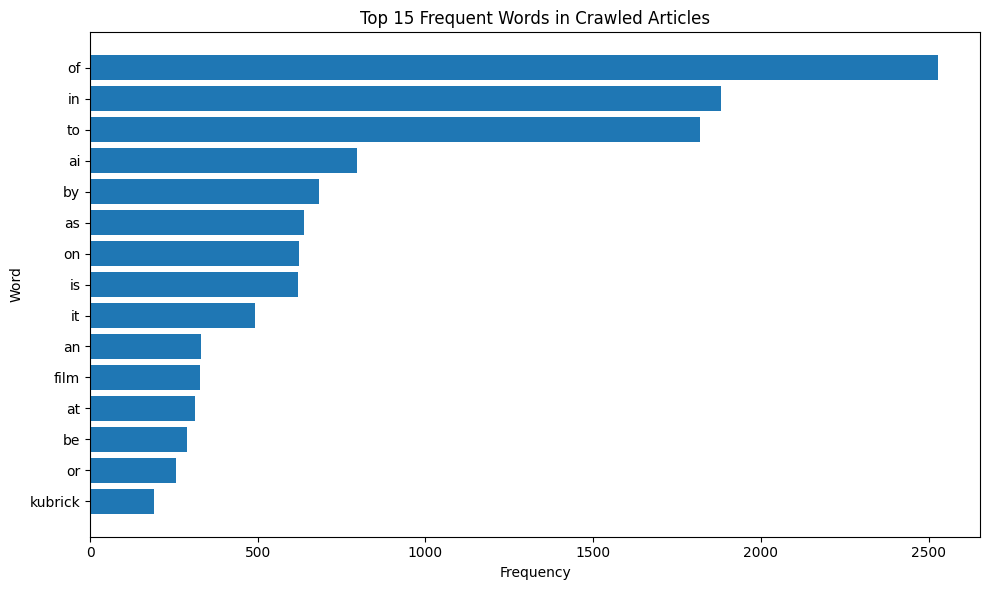

In [37]:
# Purpose: Visualize the 15 most frequent words in the collected article text.

top_words = word_counts.most_common(15)
words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(10, 6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Top 15 Frequent Words in Crawled Articles")
plt.tight_layout()
plt.show()

In [38]:
# Purpose: Keep links between the 30 crawled articles for network analysis.

article_titles = set(pages_df["title"])

network_df = links_df[
    links_df["source"].isin(article_titles)
    & links_df["target"].isin(article_titles)
].copy()

network_df = network_df.drop_duplicates(
    subset=["source", "target"]
)

print("Crawled articles:", len(article_titles))
print("Internal links:", len(network_df))
print("\nSample network links:")
display(network_df.head(10))

Crawled articles: 30
Internal links: 90

Sample network links:


,source,target
0,Artificial intelligence,15.ai
1,Artificial intelligence,1X Technologies
2,Artificial intelligence,2001: A Space Odyssey
3,Artificial intelligence,2001: A Space Odyssey (novel)
4,Artificial intelligence,2024 Indian general election
5,Artificial intelligence,2026 cyberattacks by rogue OpenAI agents
6,Artificial intelligence,3D optical data storage
7,Artificial intelligence,A* search algorithm
8,Artificial intelligence,A.I. Artificial Intelligence
10,Artificial intelligence,ABB


In [43]:
# Purpose: Remove common English stop words for meaningful text analysis.

stop_words.update({
    "of", "in", "to", "by", "as", "on", "is", "it", "an",
    "at", "be", "or", "he", "she", "they", "we", "i",
    "a", "the", "and", "for", "that", "with", "from",
    "this", "are", "was", "were", "has", "have", "had",
    "will", "would", "can", "could", "also", "been",
    "which", "who", "its", "their", "these", "those"
})

all_words = [
    word
    for tokens in pages_df["tokens"]
    for word in tokens
    if word not in stop_words
]

word_counts = Counter(all_words)

print("Top 20 meaningful words:")
print(word_counts.most_common(20))

Top 20 meaningful words:
[('ai', 796), ('film', 328), ('kubrick', 190), ('intelligence', 180), ('artificial', 156), ('abb', 156), ('human', 132), ('first', 131), ('research', 121), ('data', 116), ('may', 107), ('million', 99), ('including', 98), ('space', 94), ('time', 94), ('act', 94), ('learning', 93), ('systems', 89), ('voice', 88), ('based', 87)]


In [54]:
# Purpose: Create an interactive chart of the 15 most frequent words.

import plotly.express as px

top_words = word_counts.most_common(15)

word_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])
word_df = word_df.sort_values("Frequency", ascending=True)

fig = px.bar(
    word_df,
    x="Frequency",
    y="Word",
    orientation="h",
    color="Frequency",
    color_continuous_scale="Viridis",
    title="Top 15 Words in Crawled Wikipedia Articles",
    hover_data={"Frequency": True, "Word": True}
)

fig.update_layout(
    template="plotly_white",
    height=600,
    coloraxis_showscale=False
)
fig.write_html("project_outputs/word_frequency.html")
fig.show()

In [55]:
# Purpose: Build the hyperlink network and calculate node connectivity.

G = nx.DiGraph()

G.add_nodes_from(pages_df["title"])
G.add_edges_from(
    zip(network_df["source"], network_df["target"])
)

in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

degree_df = pd.DataFrame({
    "Article": list(G.nodes()),
    "Incoming Links": [in_degree[n] for n in G.nodes()],
    "Outgoing Links": [out_degree[n] for n in G.nodes()]
})

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

print("\nTop 10 articles by incoming links:")
display(
    degree_df.sort_values("Incoming Links", ascending=False).head(10)
)

print("\nTop 10 articles by outgoing links:")
display(
    degree_df.sort_values("Outgoing Links", ascending=False).head(10)
)

Nodes: 30
Edges: 90

Top 10 articles by incoming links:


,Article,Incoming Links,Outgoing Links
0,Artificial intelligence,20,26
28,AI winter,7,8
19,AI-induced psychosis,5,6
16,ACT-R,4,4
3,2001: A Space Odyssey,4,3
1,15.ai,4,5
17,AI-assisted software development,4,5
26,AI Safety Summit 2023,3,1
18,AI-generated violent extremist content,3,3
20,AI21 Labs,3,1



Top 10 articles by outgoing links:


,Article,Incoming Links,Outgoing Links
0,Artificial intelligence,20,26
28,AI winter,7,8
19,AI-induced psychosis,5,6
17,AI-assisted software development,4,5
1,15.ai,4,5
16,ACT-R,4,4
3,2001: A Space Odyssey,4,3
25,Artificial intelligence safety institute,0,3
14,ACM SIGEVO,3,3
18,AI-generated violent extremist content,3,3


In [56]:
# Purpose: Visualize the Wikipedia hyperlink network interactively.

import plotly.graph_objects as go
import numpy as np

# Create a reproducible network layout.
pos = nx.spring_layout(G, seed=42, k=0.8, iterations=100)

# Prepare edge coordinates.
edge_x, edge_y = [], []

for source, target in G.edges():
    x0, y0 = pos[source]
    x1, y1 = pos[target]

    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x,
    y=edge_y,
    mode="lines",
    line=dict(width=0.7, color="rgba(120,120,120,0.4)"),
    hoverinfo="skip",
    name="Hyperlinks"
)

# Assign node colors based on incoming-link counts.
node_x = [pos[n][0] for n in G.nodes()]
node_y = [pos[n][1] for n in G.nodes()]
node_names = list(G.nodes())
node_in = [in_degree[n] for n in node_names]
node_out = [out_degree[n] for n in node_names]

node_trace = go.Scatter(
    x=node_x,
    y=node_y,
    mode="markers+text",
    text=node_names,
    textposition="top center",
    textfont=dict(size=9),
    customdata=np.column_stack([node_in, node_out]),
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Incoming links: %{customdata[0]}<br>"
        "Outgoing links: %{customdata[1]}"
        "<extra></extra>"
    ),
    marker=dict(
        size=[12 + 3 * d for d in node_in],
        color=node_in,
        colorscale="Turbo",
        showscale=True,
        colorbar=dict(title="Incoming<br>links"),
        line=dict(width=1, color="white")
    ),
    name="Articles"
)

fig = go.Figure(data=[edge_trace, node_trace])

fig.update_layout(
    title="Interactive Wikipedia Article Hyperlink Network",
    template="plotly_dark",
    showlegend=False,
    hovermode="closest",
    height=800,
    margin=dict(l=20, r=20, t=60, b=20),
    xaxis=dict(visible=False),
    yaxis=dict(visible=False)
)

fig.show()

In [57]:
# Purpose: Export interactive visualizations and analysis results.

from pathlib import Path

output_dir = Path("project_outputs")
output_dir.mkdir(exist_ok=True)

# Save interactive charts.
fig.write_html(output_dir / "wikipedia_network.html")

In [58]:

# Script 21: Export project datasets, interactive graphs, and statistics

from pathlib import Path
import shutil
import pandas as pd
import zipfile

# 1. Create output folder
output_dir = Path("project_outputs")
output_dir.mkdir(exist_ok=True)

# 2. Save datasets
pages_df.drop(columns=["tokens"], errors="ignore").to_csv(
    output_dir / "wikipedia_articles.csv", index=False
)
links_df.to_csv(output_dir / "all_wikipedia_links.csv", index=False)
network_df.to_csv(output_dir / "internal_links.csv", index=False)
degree_df.to_csv(output_dir / "network_statistics.csv", index=False)

# 3. Recreate the interactive word-frequency chart
top_words = word_counts.most_common(15)
word_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])

word_fig = px.bar(
    word_df.sort_values("Frequency"),
    x="Frequency",
    y="Word",
    orientation="h",
    color="Frequency",
    color_continuous_scale="Viridis",
    title="Top 15 Words in Crawled Wikipedia Articles"
)
word_fig.update_layout(template="plotly_white", height=600)
word_fig.write_html(output_dir / "word_frequency.html")

# 4. Recreate the interactive network graph
pos = nx.spring_layout(G, seed=42, k=0.8, iterations=100)

edge_x, edge_y = [], []
for source, target in G.edges():
    x0, y0 = pos[source]
    x1, y1 = pos[target]
    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(
    x=edge_x, y=edge_y, mode="lines",
    line=dict(width=0.7, color="rgba(150,150,150,0.45)"),
    hoverinfo="skip"
)

nodes = list(G.nodes())
node_trace = go.Scatter(
    x=[pos[n][0] for n in nodes],
    y=[pos[n][1] for n in nodes],
    mode="markers+text",
    text=nodes,
    textposition="top center",
    textfont=dict(size=9),
    customdata=[[in_degree[n], out_degree[n]] for n in nodes],
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Incoming links: %{customdata[0]}<br>"
        "Outgoing links: %{customdata[1]}<extra></extra>"
    ),
    marker=dict(
        size=[12 + 3 * in_degree[n] for n in nodes],
        color=[in_degree[n] for n in nodes],
        colorscale="Turbo",
        showscale=True,
        colorbar=dict(title="Incoming links"),
        line=dict(width=1, color="white")
    )
)

network_fig = go.Figure([edge_trace, node_trace])
network_fig.update_layout(
    title="Interactive Wikipedia Article Hyperlink Network",
    template="plotly_dark",
    showlegend=False,
    hovermode="closest",
    height=800,
    xaxis=dict(visible=False),
    yaxis=dict(visible=False)
)
network_fig.write_html(output_dir / "wikipedia_network.html")

# 5. Save the top-word frequency table
pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
).to_csv(output_dir / "top_words.csv", index=False)

# 6. Package everything into one ZIP file
zip_path = Path("wikipedia_crawler_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for file in output_dir.iterdir():
        if file.is_file():
            archive.write(file, arcname=f"project_outputs/{file.name}")

print("SUCCESS! All outputs saved.")
print("Folder:", output_dir.resolve())
print("ZIP:", zip_path.resolve())
print("\nFiles created:")
for file in sorted(output_dir.iterdir()):
    print("-", file.name)


SUCCESS! All outputs saved.
Folder: /content/project_outputs
ZIP: /content/wikipedia_crawler_outputs.zip

Files created:
- all_wikipedia_links.csv
- internal_links.csv
- network_statistics.csv
- top_words.csv
- wikipedia_articles.csv
- wikipedia_network.html
- word_frequency.html


In [59]:
from google.colab import files
files.download("wikipedia_crawler_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
%pip -q install feedparser beautifulsoup4 requests pandas

import os
import json
import time
import hashlib
import logging
import requests
import feedparser
import pandas as pd

from bs4 import BeautifulSoup
from urllib.parse import urlparse, urljoin
from urllib.robotparser import RobotFileParser
from datetime import datetime, timezone
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/DWM_Web_Crawler"
os.makedirs(BASE_DIR, exist_ok=True)

print("Libraries ready.")
print("Data directory:", BASE_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 2.6 MB/s eta 0:00:00
Mounted at /content/drive
Libraries ready.
Data directory: /content/drive/MyDrive/DWM_Web_Crawler


In [61]:
# Configure sources and crawling rules
SOURCES = {
    "BBC World": {
        "feed_url": "https://feeds.bbci.co.uk/news/world/rss.xml",
        "category": "news"
    },
    "NASA": {
        "feed_url": "https://www.nasa.gov/news-release/feed/",
        "category": "science"
    },
    "arXiv AI": {
        "feed_url": "https://export.arxiv.org/rss/cs.AI",
        "category": "research"
    }
}

KEYWORDS = [
    "artificial intelligence",
    "machine learning",
    "data mining"
]

MAX_ARTICLES = 30
REQUEST_TIMEOUT = 15
REQUEST_DELAY_SECONDS = 2

# Set to True to skip URLs already present in the previous crawl.
INCREMENTAL_MODE = True

# The crawler will identify candidate URLs from RSS feeds,
# then check robots.txt before fetching article pages.
USER_AGENT = "DWMStudentResearchCrawler/1.0 (educational project)"

print("Configured sources:", len(SOURCES))
print("Search keywords:", KEYWORDS)

Configured sources: 3
Search keywords: ['artificial intelligence', 'machine learning', 'data mining']


In [62]:
# Create logging, duplicate detection and robots.txt checks
LOG_FILE = os.path.join(BASE_DIR, "crawler.log")
STATE_FILE = os.path.join(BASE_DIR, "crawl_state.json")
DATA_FILE = os.path.join(BASE_DIR, "articles.csv")

logging.basicConfig(
    filename=LOG_FILE,
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    force=True
)

session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT})

robots_cache = {}

def log_event(level, message):
    getattr(logging, level.lower())(message)
    print(f"[{level.upper()}] {message}")

def load_previous_state():
    if os.path.exists(STATE_FILE):
        with open(STATE_FILE, "r", encoding="utf-8") as f:
            return json.load(f)
    return {"seen_urls": [], "last_run": None}

def save_state(seen_urls):
    state = {
        "seen_urls": sorted(set(seen_urls)),
        "last_run": datetime.now(timezone.utc).isoformat()
    }
    with open(STATE_FILE, "w", encoding="utf-8") as f:
        json.dump(state, f, indent=2)

def normalize_url(url):
    """Remove fragments and normalize the URL for deduplication."""
    from urllib.parse import urldefrag
    return urldefrag(url.strip())[0].rstrip("/")

def content_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

def robots_allowed(url):
    """Return False if robots.txt disallows the URL or cannot be checked."""
    parsed = urlparse(url)

    if parsed.scheme not in ("http", "https") or not parsed.netloc:
        return False

    origin = f"{parsed.scheme}://{parsed.netloc}"

    if origin not in robots_cache:
        robots_url = urljoin(origin, "/robots.txt")
        parser = RobotFileParser()
        parser.set_url(robots_url)

        try:
            response = session.get(
                robots_url,
                timeout=REQUEST_TIMEOUT
            )

            if response.status_code == 200:
                parser.parse(response.text.splitlines())
                robots_cache[origin] = parser
            elif response.status_code in (401, 403):
                robots_cache[origin] = None
                log_event("WARNING", f"Robots access denied: {origin}")
            else:
                # Fail closed when the policy cannot be verified.
                robots_cache[origin] = None
                log_event(
                    "WARNING",
                    f"Could not verify robots.txt for {origin}: "
                    f"HTTP {response.status_code}"
                )

        except requests.RequestException as e:
            robots_cache[origin] = None
            log_event("ERROR", f"Robots check failed for {origin}: {e}")

    parser = robots_cache[origin]

    if parser is None:
        return False

    return parser.can_fetch(USER_AGENT, url)

previous_state = load_previous_state()
seen_urls = set(previous_state.get("seen_urls", []))

print("Previously seen URLs:", len(seen_urls))
print("Logging file:", LOG_FILE)
print("Robots policy checker ready.")

Previously seen URLs: 0
Logging file: /content/drive/MyDrive/DWM_Web_Crawler/crawler.log
Robots policy checker ready.


In [63]:
# Fetch RSS feeds and prioritize candidate URLs
candidates = []
feed_errors = []

for source_name, config in SOURCES.items():
    feed_url = config["feed_url"]

    try:
        # Check policy before requesting the feed itself.
        if not robots_allowed(feed_url):
            log_event("WARNING", f"Skipped feed due to robots policy: {source_name}")
            continue

        time.sleep(REQUEST_DELAY_SECONDS)

        response = session.get(
            feed_url,
            timeout=REQUEST_TIMEOUT
        )
        response.raise_for_status()

        feed = feedparser.parse(response.content)

        if not feed.entries:
            log_event("WARNING", f"No entries found in feed: {source_name}")
            continue

        for entry in feed.entries:
            url = entry.get("link", "").strip()
            title = BeautifulSoup(
                entry.get("title", ""),
                "html.parser"
            ).get_text(" ", strip=True)

            summary = BeautifulSoup(
                entry.get("summary", ""),
                "html.parser"
            ).get_text(" ", strip=True)

            if not url or not title:
                continue

            url = normalize_url(url)
            searchable_text = f"{title} {summary}".lower()

            matched_keywords = [
                keyword for keyword in KEYWORDS
                if keyword.lower() in searchable_text
            ]

            # Prioritize keyword matches, but retain other candidates
            # at a lower priority so the crawler can still collect data.
            priority = 2 if matched_keywords else 1

            candidates.append({
                "source": source_name,
                "category": config["category"],
                "title": title,
                "url": url,
                "summary": summary,
                "matched_keywords": ", ".join(matched_keywords),
                "priority": priority
            })

        log_event(
            "INFO",
            f"{source_name}: found {len(feed.entries)} feed entries"
        )

    except (requests.RequestException, Exception) as e:
        feed_errors.append({
            "source": source_name,
            "error": str(e)
        })
        log_event("ERROR", f"Feed failed for {source_name}: {e}")

# Remove duplicate URLs from this batch.
candidate_df = pd.DataFrame(candidates)

if not candidate_df.empty:
    candidate_df = candidate_df.drop_duplicates(
        subset=["url"]
    )

    candidate_df = candidate_df.sort_values(
        by=["priority", "source", "title"],
        ascending=[False, True, True]
    ).reset_index(drop=True)

print("\nUnique candidate URLs:", len(candidate_df))
print("Feed errors:", len(feed_errors))

if not candidate_df.empty:
    display(candidate_df.head(10))
else:
    print("No candidates collected. Check feed access and the log.")

[INFO] BBC World: found 36 feed entries
[INFO] NASA: found 10 feed entries
[WARNING] Skipped feed due to robots policy: arXiv AI

Unique candidate URLs: 46
Feed errors: 0


,source,category,title,url,summary,matched_keywords,priority
0,BBC World,news,'It's really hard to believe' - How Oregon pri...,https://www.bbc.co.uk/news/videos/cwe8r29mjd05...,"Three children aged 5, 8 and 11 and a teacher ...",,1
1,BBC World,news,Actor Imran Khan ordered to leave India after ...,https://www.bbc.co.uk/news/articles/ck3r5pv5j1...,The Bollywood actor had been detained and rele...,,1
2,BBC World,news,Albanian protests turn violent: What we know,https://www.bbc.co.uk/news/articles/cqdjv90d1j...,Albania's capital Tirana has seen months of pr...,,1
3,BBC World,news,Are student protests being manipulated ahead o...,https://www.bbc.co.uk/news/articles/c8zxlyg965...,France's prime minister has suggested that stu...,,1
4,BBC World,news,At least 33 pupils and teacher killed after sc...,https://www.bbc.co.uk/news/articles/cked326lld...,Children were buried under the debris after th...,,1
5,BBC World,news,At the Brooklyn shop in 'surreal' row with Kel...,https://www.bbc.co.uk/news/articles/cxvgdneplg...,Art of Play says its staff have been threatene...,,1
6,BBC World,news,Brazil's Congress approves shorter working wee...,https://www.bbc.co.uk/news/articles/cmwy43pp08...,Lula's supporters hope the measure will boost ...,,1
7,BBC World,news,Bus hits train stopped on French side of Chann...,https://www.bbc.co.uk/news/articles/c6wyrnmgzn...,Two people were airlifted to hospital but no-o...,,1
8,BBC World,news,China tells Israel to stop 'forced establishme...,https://www.bbc.co.uk/news/articles/cq1j3wdxy4...,Chinese Foreign Minister Wang Yi spoke to Isra...,,1
9,BBC World,news,"Dad fined after son, 2, died in Cyprus hotel fall",https://www.bbc.co.uk/news/articles/cvj6j1klez...,"Joshua Foster ""lost control"" of his son while ...",,1


In [64]:
# ============================================================
# CELL 5: LOAD PREVIOUS DATA
# Purpose:
#   Load articles from earlier runs so that we can perform
#   incremental crawling instead of collecting everything again.
# ============================================================

# Define a separate file for crawl errors.
ERROR_FILE = os.path.join(BASE_DIR, "crawl_errors.csv")

# Load existing article records if the CSV already exists.
if os.path.exists(DATA_FILE):
    articles_df = pd.read_csv(DATA_FILE)

    # Ensure the key columns exist before using previous records.
    if "url" not in articles_df.columns:
        articles_df["url"] = ""

    if "content_hash" not in articles_df.columns:
        articles_df["content_hash"] = ""

    # Store previously collected URLs for quick duplicate checks.
    stored_urls = set(
        articles_df["url"].dropna().astype(str).map(normalize_url)
    )

    # Store hashes of previously collected article content.
    stored_hashes = set(
        articles_df["content_hash"].dropna().astype(str)
    )

else:
    # Create an empty table on the first run.
    articles_df = pd.DataFrame()
    stored_urls = set()
    stored_hashes = set()

print("Previously stored articles:", len(articles_df))
print("Previously stored URLs:", len(stored_urls))
print("Previously stored content hashes:", len(stored_hashes))

Previously stored articles: 0
Previously stored URLs: 0
Previously stored content hashes: 0


In [65]:
# ============================================================
# CELL 6: ARTICLE TEXT EXTRACTION
# Purpose:
#   Download an article page and extract its main readable text.
# ============================================================

def extract_article(url):
    """
    Fetch one webpage and extract its title and readable text.

    Returns a dictionary containing the article information.
    Raises an exception if the request fails.
    """

    # Check the site's robots.txt before accessing the article.
    if not robots_allowed(url):
        raise PermissionError(
            "URL disallowed by robots.txt or policy could not be verified"
        )

    # Wait between page requests to reduce server load.
    time.sleep(REQUEST_DELAY_SECONDS)

    # Download the page with a timeout.
    response = session.get(
        url,
        timeout=REQUEST_TIMEOUT
    )

    # Raise an error for HTTP failures such as 403 or 404.
    response.raise_for_status()

    # Parse the HTML document.
    soup = BeautifulSoup(response.text, "html.parser")

    # Remove elements that generally do not contain article content.
    for element in soup([
        "script", "style", "nav", "footer",
        "header", "aside", "noscript"
    ]):
        element.decompose()

    # Extract the page title, falling back to an empty string.
    title_tag = soup.find("title")
    page_title = (
        title_tag.get_text(" ", strip=True)
        if title_tag else ""
    )

    # Prefer the main article area when the page provides one.
    main_content = soup.find("main") or soup.find("article")

    # Otherwise, use the remaining page body.
    if main_content is None:
        main_content = soup.body or soup

    # Extract text and normalize repeated whitespace.
    text_content = main_content.get_text(" ", strip=True)
    text_content = " ".join(text_content.split())

    # Return the extracted information.
    return {
        "page_title": page_title,
        "text": text_content,
        "status_code": response.status_code,
        "content_hash": content_hash(text_content)
    }

print("Article extraction function is ready.")

Article extraction function is ready.


In [66]:
# ============================================================
# CELL 7: CRAWL AND DEDUPLICATE
# Purpose:
#   Process prioritized RSS candidates, extract content,
#   and skip duplicate URLs or duplicate article text.
# ============================================================

new_records = []
error_records = []

# Avoid processing the same URL more than once in this run.
run_urls = set()

# Use the sorted candidate list from Cell 4.
if not candidate_df.empty:

    # Limit the number of article pages processed per run.
    for _, candidate in candidate_df.head(MAX_ARTICLES).iterrows():

        url = normalize_url(candidate["url"])

        # Skip repeated URLs within the current run.
        if url in run_urls:
            continue

        run_urls.add(url)

        # Skip URLs already stored when incremental mode is enabled.
        if INCREMENTAL_MODE and url in stored_urls:
            log_event("INFO", f"Already collected; skipping: {url}")
            continue

        try:
            # Fetch and extract the article.
            extracted = extract_article(url)

            # Ignore pages that produce no useful text.
            if len(extracted["text"]) < 100:
                log_event("WARNING", f"Too little text extracted: {url}")
                continue

            # Skip content that matches a previously stored article.
            if extracted["content_hash"] in stored_hashes:
                log_event("INFO", f"Duplicate content skipped: {url}")
                continue

            # Save both feed metadata and extracted article content.
            record = {
                "source": candidate["source"],
                "category": candidate["category"],
                "title": candidate["title"],
                "page_title": extracted["page_title"],
                "url": url,
                "summary": candidate["summary"],
                "matched_keywords": candidate["matched_keywords"],
                "priority": int(candidate["priority"]),
                "text": extracted["text"],
                "word_count": len(extracted["text"].split()),
                "content_hash": extracted["content_hash"],
                "status_code": extracted["status_code"],
                "crawled_at": datetime.now(timezone.utc).isoformat()
            }

            new_records.append(record)

            # Update sets immediately to catch duplicates in this run.
            stored_urls.add(url)
            stored_hashes.add(extracted["content_hash"])

            log_event("INFO", f"Collected: {candidate['title']}")

        except Exception as e:
            # Record the URL and error rather than stopping the entire crawl.
            error_records.append({
                "source": candidate["source"],
                "title": candidate["title"],
                "url": url,
                "error": str(e),
                "time": datetime.now(timezone.utc).isoformat()
            })

            log_event("ERROR", f"Failed article: {url} | {e}")

print("\nNew articles collected:", len(new_records))
print("Article errors:", len(error_records))

[INFO] Collected: 'It's really hard to believe' - How Oregon primary school shooting unfolded
[INFO] Collected: Actor Imran Khan ordered to leave India after participating in protest
[INFO] Collected: Albanian protests turn violent: What we know
[INFO] Collected: Are student protests being manipulated ahead of France's presidential election?
[INFO] Collected: At least 33 pupils and teacher killed after school roof collapses in Pakistan
[INFO] Collected: At the Brooklyn shop in 'surreal' row with Kelly Clarkson over mechanical bird
[INFO] Collected: Brazil's Congress approves shorter working week in win for Lula
[INFO] Collected: Bus hits train stopped on French side of Channel Tunnel, with 19 injured
[INFO] Collected: China tells Israel to stop 'forced establishment' of West Bank settlements
[INFO] Collected: Dad fined after son, 2, died in Cyprus hotel fall
[INFO] Collected: Houthi missile attack on Yemeni presidential palace kills five, minister says
[INFO] Collected: India's 'cockro

In [67]:
# ============================================================
# CELL 8: SAVE RESULTS
# Purpose:
#   Persist collected articles and crawl state to Google Drive.
#   This lets later runs skip previously seen URLs.
# ============================================================

# Convert the new article records into a DataFrame.
new_df = pd.DataFrame(new_records)

# Merge new records with existing data without discarding old articles.
if not new_df.empty:
    if articles_df.empty:
        articles_df = new_df.copy()
    else:
        articles_df = pd.concat(
            [articles_df, new_df],
            ignore_index=True
        )

# Keep only one record per normalized URL.
if not articles_df.empty:
    articles_df["url"] = articles_df["url"].astype(str).map(normalize_url)
    articles_df = articles_df.drop_duplicates(
        subset=["url"],
        keep="last"
    )

    # Save the consolidated article dataset.
    articles_df.to_csv(DATA_FILE, index=False)

# Append errors so failures from earlier runs remain available.
if error_records:
    errors_df = pd.DataFrame(error_records)

    if os.path.exists(ERROR_FILE):
        old_errors = pd.read_csv(ERROR_FILE)
        errors_df = pd.concat(
            [old_errors, errors_df],
            ignore_index=True
        )

    errors_df.to_csv(ERROR_FILE, index=False)

# Save previously seen URLs and the current run time.
# This state supports incremental URL skipping in future runs.
save_state(stored_urls)

print("Total stored articles:", len(articles_df))
print("Article data:", DATA_FILE)
print("Error log:", ERROR_FILE)
print("Crawl state:", STATE_FILE)

# Display a small preview of the saved dataset.
if not articles_df.empty:
    display(
        articles_df[
            ["source", "title", "url", "word_count", "status_code"]
        ].tail(10)
    )

Total stored articles: 30
Article data: /content/drive/MyDrive/DWM_Web_Crawler/articles.csv
Error log: /content/drive/MyDrive/DWM_Web_Crawler/crawl_errors.csv
Crawl state: /content/drive/MyDrive/DWM_Web_Crawler/crawl_state.json


,source,title,url,word_count,status_code
20,BBC World,Russia accuses Ukraine of attacking oil refine...,https://www.bbc.co.uk/news/articles/cqwyrnwd9d...,1225,200
21,BBC World,School headscarf ban sparks rare protests in A...,https://www.bbc.co.uk/news/articles/cwly0g2r4k...,946,200
22,BBC World,Seven crew missing after drone attack leaves t...,https://www.bbc.co.uk/news/articles/c60qkgpp59...,699,200
23,BBC World,Ship attack reports near Hormuz reach record h...,https://www.bbc.co.uk/news/articles/cmde8dpg8g...,843,200
24,BBC World,"They fled Russia, but the West sent them back",https://www.bbc.co.uk/news/articles/c6x23qpzjk...,1493,200
25,BBC World,Tip-off foiled US teen suspect's plot to attac...,https://www.bbc.co.uk/news/articles/cqgm0j4kjv...,472,200
26,BBC World,Toxic algorithms wouldn't let them go - now Au...,https://www.bbc.co.uk/news/articles/cwr7y8er1n...,2070,200
27,BBC World,Trump calls off livestream of Fort Hood attack...,https://www.bbc.co.uk/news/articles/crx23qlnj2...,773,200
28,BBC World,Trump denies limiting Ukraine access to Starli...,https://www.bbc.co.uk/news/articles/ckz65g34wy...,685,200
29,BBC World,Two dead in Istanbul after heaviest rainfall i...,https://www.bbc.co.uk/news/articles/cq398x7j1l...,387,200


In [68]:
# ============================================================
# CELL 9: DATA QUALITY VALIDATION
# Purpose:
#   Check missing fields, duplicate URLs, duplicate content,
#   and basic article quality.
# ============================================================

if articles_df.empty:
    print("No articles stored yet. Run the earlier crawl cells first.")

else:
    required_columns = [
        "source", "title", "url", "text",
        "content_hash", "word_count"
    ]

    # Check that all expected columns are present.
    missing_columns = [
        col for col in required_columns
        if col not in articles_df.columns
    ]

    print("Missing expected columns:", missing_columns)

    # Count missing values in each available column.
    missing_values = articles_df.isna().sum().rename(
        "missing_count"
    ).to_frame()

    # Count repeated URLs and content hashes.
    duplicate_urls = articles_df["url"].duplicated().sum()

    if "content_hash" in articles_df.columns:
        duplicate_hashes = articles_df["content_hash"].duplicated().sum()
    else:
        duplicate_hashes = "Column unavailable"

    # Count records with very little extracted text.
    short_articles = (
        articles_df["text"].fillna("").str.len() < 100
    ).sum()

    print("\nStored articles:", len(articles_df))
    print("Duplicate URLs:", duplicate_urls)
    print("Duplicate content hashes:", duplicate_hashes)
    print("Articles with fewer than 100 characters:", short_articles)

    display(missing_values)

Missing expected columns: []

Stored articles: 30
Duplicate URLs: 0
Duplicate content hashes: 0
Articles with fewer than 100 characters: 0


,missing_count
source,0
category,0
title,0
page_title,0
url,0
summary,0
matched_keywords,0
priority,0
text,0
word_count,0


In [69]:
# ============================================================
# CELL 10: INCREMENTAL CHANGE DETECTION
# Purpose:
#   Re-fetch selected stored URLs and compare their content
#   hashes with the previously stored hashes.
#
# Note:
#   This is an explicit revalidation pass. It is not a scheduler.
# ============================================================

change_records = []
updated_records = []

# Set a small limit to avoid making too many requests at once.
REVALIDATE_LIMIT = 10

if articles_df.empty:
    print("No stored articles available for revalidation.")

else:
    # Revalidate only the most recently stored URLs.
    sample_df = articles_df.tail(REVALIDATE_LIMIT)

    for _, row in sample_df.iterrows():
        url = normalize_url(str(row["url"]))

        try:
            # Extract the current version of the stored article.
            current = extract_article(url)

            old_hash = str(row.get("content_hash", ""))
            new_hash = current["content_hash"]

            # Record whether the page appears unchanged or modified.
            changed = old_hash != new_hash

            change_records.append({
                "url": url,
                "title": row.get("title", ""),
                "old_hash": old_hash,
                "new_hash": new_hash,
                "changed": changed,
                "checked_at": datetime.now(timezone.utc).isoformat(),
                "status": "success"
            })

            # If changed, update the saved article content and metadata.
            if changed:
                updated = row.to_dict()
                updated["text"] = current["text"]
                updated["page_title"] = current["page_title"]
                updated["content_hash"] = new_hash
                updated["word_count"] = len(current["text"].split())
                updated["status_code"] = current["status_code"]
                updated["crawled_at"] = datetime.now(timezone.utc).isoformat()

                updated_records.append(updated)

            log_event(
                "INFO",
                f"Revalidated: {url} | changed={changed}"
            )

        except Exception as e:
            # Record revalidation failures instead of stopping the loop.
            change_records.append({
                "url": url,
                "title": row.get("title", ""),
                "old_hash": str(row.get("content_hash", "")),
                "new_hash": "",
                "changed": False,
                "checked_at": datetime.now(timezone.utc).isoformat(),
                "status": f"failed: {e}"
            })

            log_event("ERROR", f"Revalidation failed: {url} | {e}")

# Save the revalidation history separately.
changes_file = os.path.join(BASE_DIR, "change_history.csv")

changes_df = pd.DataFrame(change_records)

if not changes_df.empty:
    if os.path.exists(changes_file):
        old_changes = pd.read_csv(changes_file)
        changes_df = pd.concat(
            [old_changes, changes_df],
            ignore_index=True
        )

    changes_df.to_csv(changes_file, index=False)

# Apply updated article versions to the main dataset.
if updated_records:
    updated_df = pd.DataFrame(updated_records)

    # Use URL as the record key.
    articles_df = articles_df.set_index("url")
    updated_df = updated_df.set_index("url")

    articles_df.update(updated_df)

    # Restore newly added fields if the existing dataset lacked them.
    for col in updated_df.columns:
        if col not in articles_df.columns:
            articles_df[col] = updated_df[col]

    articles_df = articles_df.reset_index()
    articles_df.to_csv(DATA_FILE, index=False)

print("URLs checked:", len(change_records))
print("Changed articles detected:", sum(
    item["changed"] for item in change_records
    if item["status"] == "success"
))
print("Change history:", changes_file)

[INFO] Revalidated: https://www.bbc.co.uk/news/articles/cqwyrnwd9dw1o?at_medium=RSS&at_campaign=rss | changed=False
[INFO] Revalidated: https://www.bbc.co.uk/news/articles/cwly0g2r4k3po?at_medium=RSS&at_campaign=rss | changed=False
[INFO] Revalidated: https://www.bbc.co.uk/news/articles/c60qkgpp592yo?at_medium=RSS&at_campaign=rss | changed=False
[INFO] Revalidated: https://www.bbc.co.uk/news/articles/cmde8dpg8g0no?at_medium=RSS&at_campaign=rss | changed=False
[INFO] Revalidated: https://www.bbc.co.uk/news/articles/c6x23qpzjklwo?at_medium=RSS&at_campaign=rss | changed=False
[INFO] Revalidated: https://www.bbc.co.uk/news/articles/cqgm0j4kjvevo?at_medium=RSS&at_campaign=rss | changed=False
[INFO] Revalidated: https://www.bbc.co.uk/news/articles/cwr7y8er1n8vo?at_medium=RSS&at_campaign=rss | changed=False
[INFO] Revalidated: https://www.bbc.co.uk/news/articles/crx23qlnj27qo?at_medium=RSS&at_campaign=rss | changed=False
[INFO] Revalidated: https://www.bbc.co.uk/news/articles/ckz65g34wyd8o?at

In [70]:
# ============================================================
# CELL 11: SUMMARY TABLES
# Purpose:
#   Prepare dashboard metrics about collected articles,
#   word counts, source distribution, and crawl errors.
# ============================================================

if articles_df.empty:
    print("No data available for the dashboard yet.")

else:
    # Summarize article collection by source.
    source_summary = (
        articles_df.groupby("source")
        .agg(
            articles=("url", "count"),
            average_words=("word_count", "mean"),
            total_words=("word_count", "sum")
        )
        .reset_index()
    )

    source_summary["average_words"] = (
        source_summary["average_words"].round(1)
    )

    # Calculate overall data quality metrics.
    total_articles = len(articles_df)
    unique_urls = articles_df["url"].nunique()
    total_words = articles_df["word_count"].fillna(0).sum()

    if os.path.exists(ERROR_FILE):
        errors_df = pd.read_csv(ERROR_FILE)
        total_errors = len(errors_df)
    else:
        errors_df = pd.DataFrame()
        total_errors = 0

    if os.path.exists(changes_file):
        history_df = pd.read_csv(changes_file)
        successful_checks = (
            history_df["status"].astype(str).eq("success").sum()
        )
    else:
        successful_checks = 0

    # Save source summary for the report.
    summary_file = os.path.join(BASE_DIR, "source_summary.csv")
    source_summary.to_csv(summary_file, index=False)

    print("CRAWL SUMMARY")
    print("-------------")
    print("Stored articles:", total_articles)
    print("Unique URLs:", unique_urls)
    print("Total extracted words:", int(total_words))
    print("Recorded article errors:", total_errors)
    print("Successful revalidation checks:", successful_checks)

    display(source_summary)

CRAWL SUMMARY
-------------
Stored articles: 30
Unique URLs: 30
Total extracted words: 25065
Recorded article errors: 0
Successful revalidation checks: 10


,source,articles,average_words,total_words
0,BBC World,30,835.5,25065


# DWM Web Crawler Dashboard

**Last dashboard refresh:** 2026-10-16 20:54 UTC


        | Metric | Value |
        |---|---:|
        | Articles stored | 30 |
        | Unique URLs | 30 |
        | Sources represented | 1 |
        | Total extracted words | 25065 |
        | Recorded article errors | 0 |
        

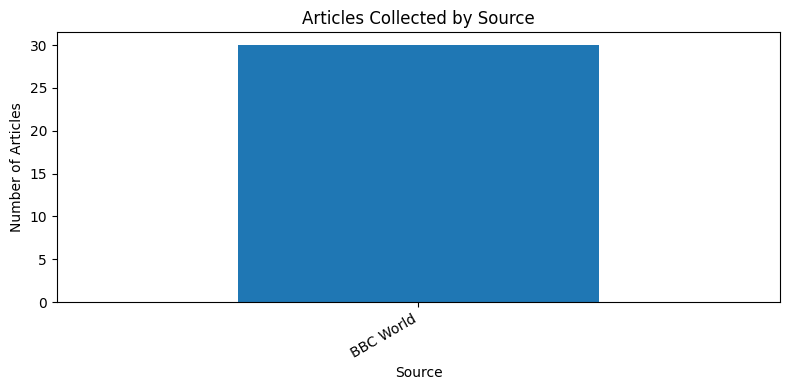

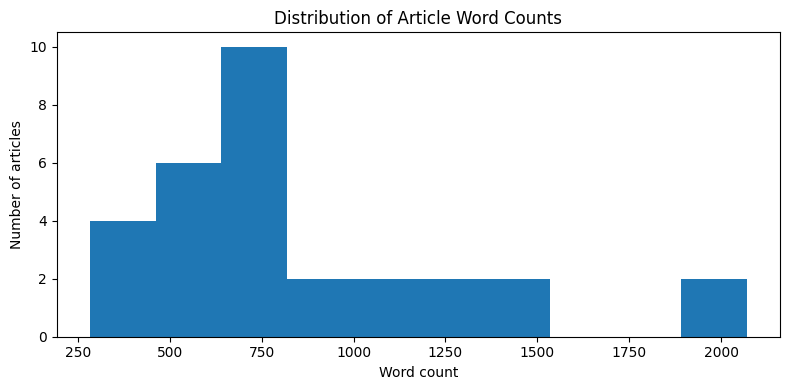

## Latest collected articles

,source,title,url,word_count
20,BBC World,Russia accuses Ukraine of attacking oil refine...,https://www.bbc.co.uk/news/articles/cqwyrnwd9d...,1225
21,BBC World,School headscarf ban sparks rare protests in A...,https://www.bbc.co.uk/news/articles/cwly0g2r4k...,946
22,BBC World,Seven crew missing after drone attack leaves t...,https://www.bbc.co.uk/news/articles/c60qkgpp59...,699
23,BBC World,Ship attack reports near Hormuz reach record h...,https://www.bbc.co.uk/news/articles/cmde8dpg8g...,843
24,BBC World,"They fled Russia, but the West sent them back",https://www.bbc.co.uk/news/articles/c6x23qpzjk...,1493
25,BBC World,Tip-off foiled US teen suspect's plot to attac...,https://www.bbc.co.uk/news/articles/cqgm0j4kjv...,472
26,BBC World,Toxic algorithms wouldn't let them go - now Au...,https://www.bbc.co.uk/news/articles/cwr7y8er1n...,2070
27,BBC World,Trump calls off livestream of Fort Hood attack...,https://www.bbc.co.uk/news/articles/crx23qlnj2...,773
28,BBC World,Trump denies limiting Ukraine access to Starli...,https://www.bbc.co.uk/news/articles/ckz65g34wy...,685
29,BBC World,Two dead in Istanbul after heaviest rainfall i...,https://www.bbc.co.uk/news/articles/cq398x7j1l...,387


Dashboard displayed successfully.


In [71]:
# ============================================================
# CELL 12: SIMPLE NOTEBOOK DASHBOARD
# Purpose:
#   Show headline metrics, source counts, article lengths,
#   and the latest crawl records directly inside Colab.
# ============================================================

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if articles_df.empty:
    display(Markdown("## DWM Web Crawler Dashboard\nNo articles collected yet."))

else:
    display(Markdown("# DWM Web Crawler Dashboard"))
    display(Markdown(
        f"**Last dashboard refresh:** "
        f"{datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}"
    ))

    # Show headline metrics.
    display(Markdown(
        f"""
        | Metric | Value |
        |---|---:|
        | Articles stored | {len(articles_df)} |
        | Unique URLs | {articles_df['url'].nunique()} |
        | Sources represented | {articles_df['source'].nunique()} |
        | Total extracted words | {int(articles_df['word_count'].fillna(0).sum())} |
        | Recorded article errors | {total_errors if 'total_errors' in globals() else 0} |
        """
    ))

    # Chart 1: Number of articles collected from each source.
    source_counts = articles_df["source"].value_counts()

    plt.figure(figsize=(8, 4))
    source_counts.plot(kind="bar")
    plt.title("Articles Collected by Source")
    plt.xlabel("Source")
    plt.ylabel("Number of Articles")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    # Chart 2: Distribution of extracted article lengths.
    plt.figure(figsize=(8, 4))
    articles_df["word_count"].dropna().plot(
        kind="hist",
        bins=10
    )
    plt.title("Distribution of Article Word Counts")
    plt.xlabel("Word count")
    plt.ylabel("Number of articles")
    plt.tight_layout()
    plt.show()

    # Show the latest collected records.
    display(Markdown("## Latest collected articles"))
    display(
        articles_df[
            ["source", "title", "url", "word_count"]
        ].tail(10)
    )

    print("Dashboard displayed successfully.")

In [72]:
# ============================================================
# CELL 13: CRAWL RUN SUMMARY
# Purpose:
#   Summarize the current run and save its metrics for reporting.
# ============================================================

RUN_SUMMARY_FILE = os.path.join(BASE_DIR, "run_history.csv")

# Count the results from the most recent crawl.
run_summary = {
    "run_time_utc": datetime.now(timezone.utc).isoformat(),
    "candidate_urls": len(candidate_df) if "candidate_df" in globals() else 0,
    "new_articles_this_run": len(new_records) if "new_records" in globals() else 0,
    "total_stored_articles": len(articles_df) if "articles_df" in globals() else 0,
    "article_errors_this_run": len(error_records) if "error_records" in globals() else 0,
    "sources_configured": len(SOURCES),
    "keywords_configured": ", ".join(KEYWORDS)
}

run_df = pd.DataFrame([run_summary])

# Append the current run to the historical summary.
if os.path.exists(RUN_SUMMARY_FILE):
    previous_runs = pd.read_csv(RUN_SUMMARY_FILE)
    run_df = pd.concat([previous_runs, run_df], ignore_index=True)

run_df.to_csv(RUN_SUMMARY_FILE, index=False)

print("Run summary saved:", RUN_SUMMARY_FILE)
display(run_df.tail(5))

Run summary saved: /content/drive/MyDrive/DWM_Web_Crawler/run_history.csv


,run_time_utc,candidate_urls,new_articles_this_run,total_stored_articles,article_errors_this_run,sources_configured,keywords_configured
0,2026-10-16T20:55:02.544815+00:00,46,30,30,0,3,"artificial intelligence, machine learning, dat..."


In [73]:
# ============================================================
# CELL 14: REUSABLE CRAWL FUNCTION
# Purpose:
#   Re-run the configured RSS discovery and article collection.
#   The function uses the previously defined crawler functions.
# ============================================================

def run_crawler_once():
    """Run one discovery-and-collection cycle."""

    global candidate_df, new_records, error_records
    global articles_df, stored_urls, stored_hashes

    print("\nStarting crawler run...")
    start_time = time.time()

    # Refresh persistent records before starting the next run.
    if os.path.exists(DATA_FILE):
        articles_df = pd.read_csv(DATA_FILE)
        stored_urls = set(
            articles_df["url"].dropna().astype(str).map(normalize_url)
        )
        stored_hashes = set(
            articles_df["content_hash"].dropna().astype(str)
        )

    # Rediscover candidates from the configured RSS feeds.
    candidates = []
    run_feed_errors = []

    for source_name, config in SOURCES.items():
        try:
            feed_url = config["feed_url"]

            if not robots_allowed(feed_url):
                log_event("WARNING", f"Feed skipped by policy: {source_name}")
                continue

            time.sleep(REQUEST_DELAY_SECONDS)
            response = session.get(feed_url, timeout=REQUEST_TIMEOUT)
            response.raise_for_status()

            feed = feedparser.parse(response.content)

            for entry in feed.entries:
                url = entry.get("link", "").strip()
                title = BeautifulSoup(
                    entry.get("title", ""), "html.parser"
                ).get_text(" ", strip=True)
                summary = BeautifulSoup(
                    entry.get("summary", ""), "html.parser"
                ).get_text(" ", strip=True)

                if not url or not title:
                    continue

                searchable = f"{title} {summary}".lower()
                matches = [
                    keyword for keyword in KEYWORDS
                    if keyword.lower() in searchable
                ]

                candidates.append({
                    "source": source_name,
                    "category": config["category"],
                    "title": title,
                    "url": normalize_url(url),
                    "summary": summary,
                    "matched_keywords": ", ".join(matches),
                    "priority": 2 if matches else 1
                })

        except Exception as e:
            run_feed_errors.append({
                "source": source_name,
                "error": str(e)
            })
            log_event("ERROR", f"Feed discovery failed: {source_name} | {e}")

    candidate_df = pd.DataFrame(candidates)

    if not candidate_df.empty:
        candidate_df = (
            candidate_df.drop_duplicates(subset=["url"])
            .sort_values(
                ["priority", "source", "title"],
                ascending=[False, True, True]
            )
            .reset_index(drop=True)
        )

    # Collect new article records using the same policy and deduplication
    # functions defined in earlier cells.
    new_records = []
    error_records = []

    if not candidate_df.empty:
        for _, candidate in candidate_df.head(MAX_ARTICLES).iterrows():
            url = normalize_url(candidate["url"])

            # In incremental mode, skip URLs already stored.
            if INCREMENTAL_MODE and url in stored_urls:
                continue

            try:
                extracted = extract_article(url)

                if len(extracted["text"]) < 100:
                    continue

                if extracted["content_hash"] in stored_hashes:
                    continue

                new_records.append({
                    "source": candidate["source"],
                    "category": candidate["category"],
                    "title": candidate["title"],
                    "page_title": extracted["page_title"],
                    "url": url,
                    "summary": candidate["summary"],
                    "matched_keywords": candidate["matched_keywords"],
                    "priority": int(candidate["priority"]),
                    "text": extracted["text"],
                    "word_count": len(extracted["text"].split()),
                    "content_hash": extracted["content_hash"],
                    "status_code": extracted["status_code"],
                    "crawled_at": datetime.now(timezone.utc).isoformat()
                })

                stored_urls.add(url)
                stored_hashes.add(extracted["content_hash"])

            except Exception as e:
                error_records.append({
                    "source": candidate["source"],
                    "title": candidate["title"],
                    "url": url,
                    "error": str(e),
                    "time": datetime.now(timezone.utc).isoformat()
                })

                log_event("ERROR", f"Article fetch failed: {url} | {e}")

    # Merge new records into the persistent article table.
    if new_records:
        articles_df = pd.concat(
            [articles_df, pd.DataFrame(new_records)],
            ignore_index=True
        ).drop_duplicates(subset=["url"], keep="last")

        articles_df.to_csv(DATA_FILE, index=False)

    # Append new errors to the error log.
    if error_records:
        new_errors_df = pd.DataFrame(error_records)

        if os.path.exists(ERROR_FILE):
            old_errors_df = pd.read_csv(ERROR_FILE)
            new_errors_df = pd.concat(
                [old_errors_df, new_errors_df],
                ignore_index=True
            )

        new_errors_df.to_csv(ERROR_FILE, index=False)

    # Persist URL history and save a summary for this run.
    save_state(stored_urls)

    duration = round(time.time() - start_time, 2)

    summary = {
        "run_time_utc": datetime.now(timezone.utc).isoformat(),
        "candidate_urls": len(candidate_df),
        "new_articles_this_run": len(new_records),
        "total_stored_articles": len(articles_df),
        "article_errors_this_run": len(error_records),
        "duration_seconds": duration
    }

    summary_df = pd.DataFrame([summary])

    if os.path.exists(RUN_SUMMARY_FILE):
        old_runs = pd.read_csv(RUN_SUMMARY_FILE)
        summary_df = pd.concat([old_runs, summary_df], ignore_index=True)

    summary_df.to_csv(RUN_SUMMARY_FILE, index=False)

    print("\nRun completed.")
    display(summary_df.tail(1))

    return summary

In [74]:
# ============================================================
# CELL 15: MANUAL SCHEDULING
# Purpose:
#   Demonstrate repeated crawling at a chosen interval.
#
# Warning:
#   Keep the number of runs low during testing. This loop stops
#   when the configured number of runs has completed or you
#   interrupt the Colab cell.
# ============================================================

# Set RUNS to 1 for a single test run.
RUNS = 1

# Interval between runs, in seconds.
# Example: 3600 means one hour between runs.
INTERVAL_SECONDS = 3600

for run_number in range(RUNS):
    print(f"\n========== RUN {run_number + 1} OF {RUNS} ==========")

    result = run_crawler_once()

    # Wait only if another run is scheduled in this loop.
    if run_number < RUNS - 1:
        print(f"Waiting {INTERVAL_SECONDS} seconds...")
        time.sleep(INTERVAL_SECONDS)

print("Scheduled-run demonstration finished.")


========== RUN 1 OF 1 ==========

Starting crawler run...
[WARNING] Feed skipped by policy: arXiv AI

Run completed.


,run_time_utc,candidate_urls,new_articles_this_run,total_stored_articles,article_errors_this_run,sources_configured,keywords_configured,duration_seconds
1,2026-10-16T20:55:19.594111+00:00,46,0,30,0,NaN,NaN,4.35


Scheduled-run demonstration finished.


In [75]:
# ============================================================
# CELL 16: EXPORT EVIDENCE
# Purpose:
#   Save a final set of CSVs and logs that can be used in the
#   report, along with a ZIP archive for easy download.
# ============================================================

import zipfile

# Refresh the dataset from disk if it exists.
if os.path.exists(DATA_FILE):
    articles_df = pd.read_csv(DATA_FILE)

# Export a source-level summary.
if not articles_df.empty:
    source_summary = (
        articles_df.groupby("source")
        .agg(
            articles=("url", "count"),
            total_words=("word_count", "sum"),
            average_words=("word_count", "mean")
        )
        .reset_index()
    )

    source_summary["average_words"] = source_summary["average_words"].round(1)
    source_summary.to_csv(
        os.path.join(BASE_DIR, "source_summary.csv"),
        index=False
    )

# Create a simple final report as a text file.
evidence_report = os.path.join(BASE_DIR, "evidence_summary.txt")

with open(evidence_report, "w", encoding="utf-8") as f:
    f.write("DWM WEB CRAWLER — EVIDENCE SUMMARY\n")
    f.write("=" * 40 + "\n")
    f.write(f"Generated UTC: {datetime.now(timezone.utc).isoformat()}\n")
    f.write(f"Configured sources: {len(SOURCES)}\n")
    f.write(f"Keywords: {', '.join(KEYWORDS)}\n")
    f.write(f"Articles stored: {len(articles_df)}\n")

    if not articles_df.empty:
        f.write(f"Unique URLs: {articles_df['url'].nunique()}\n")
        f.write(
            "Total extracted words: "
            f"{int(articles_df['word_count'].fillna(0).sum())}\n"
        )

    f.write("\nFiles included in this project folder:\n")
    for filename in sorted(os.listdir(BASE_DIR)):
        f.write(f"- {filename}\n")

# Package available outputs and logs into a ZIP file.
ZIP_FILE = os.path.join(BASE_DIR, "DWM_Crawler_Evidence.zip")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in os.listdir(BASE_DIR):
        filepath = os.path.join(BASE_DIR, filename)

        # Avoid placing the ZIP file inside itself.
        if filename == os.path.basename(ZIP_FILE):
            continue

        if os.path.isfile(filepath):
            archive.write(filepath, arcname=filename)

print("Evidence summary:", evidence_report)
print("Evidence ZIP:", ZIP_FILE)
print("\nFiles currently in the project folder:")
display(pd.DataFrame({"filename": sorted(os.listdir(BASE_DIR))}))

Evidence summary: /content/drive/MyDrive/DWM_Web_Crawler/evidence_summary.txt
Evidence ZIP: /content/drive/MyDrive/DWM_Web_Crawler/DWM_Crawler_Evidence.zip

Files currently in the project folder:


,filename
0,DWM_Crawler_Evidence.zip
1,articles.csv
2,change_history.csv
3,crawl_state.json
4,crawler.log
5,evidence_summary.txt
6,run_history.csv
7,source_summary.csv


In [76]:
# ============================================================
# CELL 17: VERIFY SUBMISSION FILES
# Purpose:
#   Confirm that expected output files exist in Google Drive.
# ============================================================

import os
import pandas as pd
from IPython.display import display

expected_files = [
    "articles.csv",
    "crawler.log",
    "crawl_errors.csv",
    "crawl_state.json",
    "change_history.csv",
    "run_history.csv",
    "source_summary.csv",
    "evidence_summary.txt",
    "DWM_Crawler_Evidence.zip"
]

# Check the presence and size of each expected output.
verification = []

for filename in expected_files:
    path = os.path.join(BASE_DIR, filename)

    verification.append({
        "file": filename,
        "exists": os.path.isfile(path),
        "size_bytes": os.path.getsize(path) if os.path.isfile(path) else None
    })

verification_df = pd.DataFrame(verification)
display(verification_df)

# Show basic dataset information when article data exists.
articles_path = os.path.join(BASE_DIR, "articles.csv")

if os.path.isfile(articles_path):
    check_df = pd.read_csv(articles_path)

    print("\nStored article rows:", len(check_df))
    print("Columns:", list(check_df.columns))

    if "source" in check_df.columns:
        print("\nArticles by source:")
        display(check_df["source"].value_counts().to_frame("count"))

else:
    print("\narticles.csv is missing. Check whether Cell 8 or Cell 16 ran.")

,file,exists,size_bytes
0,articles.csv,True,168697.0
1,crawler.log,True,5137.0
2,crawl_errors.csv,False,NaN
3,crawl_state.json,True,2679.0
4,change_history.csv,True,3341.0
5,run_history.csv,True,308.0
6,source_summary.csv,True,67.0
7,evidence_summary.txt,True,449.0
8,DWM_Crawler_Evidence.zip,True,68183.0



Stored article rows: 30
Columns: ['source', 'category', 'title', 'page_title', 'url', 'summary', 'matched_keywords', 'priority', 'text', 'word_count', 'content_hash', 'status_code', 'crawled_at']

Articles by source:


,count
source,
BBC World,30


In [77]:
# ============================================================
# CELL 18: DIAGNOSE SOURCE COVERAGE AND CRAWLER ERRORS
# ============================================================

import os
import pandas as pd

# 1. Show recent crawler log entries.
log_path = os.path.join(BASE_DIR, "crawler.log")

print("===== RECENT CRAWLER LOG =====")
if os.path.exists(log_path):
    with open(log_path, "r", encoding="utf-8", errors="replace") as f:
        log_lines = f.readlines()

    for line in log_lines[-60:]:
        print(line.rstrip())
else:
    print("Crawler log not found.")

# 2. Check the saved article distribution.
articles_path = os.path.join(BASE_DIR, "articles.csv")

print("\n===== SAVED ARTICLES BY SOURCE =====")
if os.path.exists(articles_path):
    df = pd.read_csv(articles_path)
    print(df["source"].fillna("Unknown").value_counts().to_string())

    print("\n===== SAVED ARTICLE STATUS CODES =====")
    if "status_code" in df.columns:
        print(df["status_code"].value_counts(dropna=False).to_string())

# 3. Check whether the error records exist in memory.
print("\n===== ERROR RECORDS =====")
if "error_records" in globals():
    print("Errors currently in memory:", len(error_records))
    if error_records:
        display(pd.DataFrame(error_records).tail(20))
    else:
        print("No errors currently recorded.")
else:
    print("error_records variable is not available.")

# 4. Check whether candidate data from the feed stage is available.
print("\n===== DISCOVERED CANDIDATES =====")
if "candidate_df" in globals() and not candidate_df.empty:
    display(
        candidate_df.groupby("source")
        .size()
        .reset_index(name="candidate_count")
    )
else:
    print("No candidate data is available in the current session.")

===== RECENT CRAWLER LOG =====
2026-10-16 20:52:12,972 | INFO | BBC World: found 36 feed entries
2026-10-16 20:52:15,261 | INFO | NASA: found 10 feed entries
2026-10-16 20:52:15,313 | WARNING | Skipped feed due to robots policy: arXiv AI
2026-10-16 20:53:24,022 | INFO | Collected: 'It's really hard to believe' - How Oregon primary school shooting unfolded
2026-10-16 20:53:26,396 | INFO | Collected: Actor Imran Khan ordered to leave India after participating in protest
2026-10-16 20:53:28,721 | INFO | Collected: Albanian protests turn violent: What we know
2026-10-16 20:53:30,795 | INFO | Collected: Are student protests being manipulated ahead of France's presidential election?
2026-10-16 20:53:32,866 | INFO | Collected: At least 33 pupils and teacher killed after school roof collapses in Pakistan
2026-10-16 20:53:34,935 | INFO | Collected: At the Brooklyn shop in 'surreal' row with Kelly Clarkson over mechanical bird
2026-10-16 20:53:37,004 | INFO | Collected: Brazil's Congress approve

,source,candidate_count
0,BBC World,36
1,NASA,10


In [78]:
# ============================================================
# CELL 19: INSPECT SOURCE CONFIGURATION AND CANDIDATE RANKING
# ============================================================

# Print the configured feeds.
print("===== CONFIGURED SOURCES =====")
for source in SOURCES:
    print(source)

# Inspect the candidate table and its columns.
print("\n===== CANDIDATE DATA =====")
if "candidate_df" in globals() and not candidate_df.empty:
    print("Columns:", list(candidate_df.columns))

    # Show how many candidates each source contributed.
    print("\nCandidates by source:")
    display(
        candidate_df.groupby("source")
        .size()
        .reset_index(name="candidate_count")
    )

    # Show the highest-ranked candidates from each source.
    display(
        candidate_df.sort_values(
            by=["source", "priority"],
            ascending=[True, False]
        ).groupby("source", group_keys=False).head(5)
    )
else:
    print("No candidate data available.")

===== CONFIGURED SOURCES =====
BBC World
NASA
arXiv AI

===== CANDIDATE DATA =====
Columns: ['source', 'category', 'title', 'url', 'summary', 'matched_keywords', 'priority']

Candidates by source:


,source,candidate_count
0,BBC World,36
1,NASA,10


,source,category,title,url,summary,matched_keywords,priority
0,BBC World,news,'It's really hard to believe' - How Oregon pri...,https://www.bbc.co.uk/news/videos/cwe8r29mjd05...,"Three children aged 5, 8 and 11 and a teacher ...",,1
1,BBC World,news,Actor Imran Khan ordered to leave India after ...,https://www.bbc.co.uk/news/articles/ck3r5pv5j1...,The Bollywood actor had been detained and rele...,,1
2,BBC World,news,Albanian protests turn violent: What we know,https://www.bbc.co.uk/news/articles/cqdjv90d1j...,Albania's capital Tirana has seen months of pr...,,1
3,BBC World,news,Are student protests being manipulated ahead o...,https://www.bbc.co.uk/news/articles/c8zxlyg965...,France's prime minister has suggested that stu...,,1
4,BBC World,news,At least 33 pupils and teacher killed after sc...,https://www.bbc.co.uk/news/articles/cked326lld...,Children were buried under the debris after th...,,1
36,NASA,science,APOD: 2026 October 16 – Chasing the Internatio...,https://science.nasa.gov/image-article/apod-20...,APOD Science APOD APOD: 2026 October 16 –… Tod...,,1
37,NASA,science,Artemis II Heat Shield After Splashdown,https://www.nasa.gov/image-article/artemis-ii-...,Shortly after NASA’s Artemis II mission splash...,,1
38,NASA,science,I Am Artemis: Allison Mjoen,https://www.nasa.gov/missions/station/i-am-art...,As the supercooled propellant flowed into the ...,,1
39,NASA,science,Isaias Dims the Gulf Coast,https://science.nasa.gov/earth/earth-observato...,High-definition images of nighttime lights sho...,,1
40,NASA,science,NASA Names Stephen Cash Marshall Space Flight ...,https://www.nasa.gov/news-release/nasa-names-s...,NASA Administrator Jared Isaacman has named St...,,1


In [79]:
# ============================================================
# CELL 20: FAIR CANDIDATE SELECTION ACROSS SOURCES
# ============================================================

import pandas as pd

# Maximum number of articles to collect in one crawl.
MAX_ARTICLES = 30

# Only include sources that passed the feed policy checks.
# arXiv was skipped by the robots policy, so it is excluded.
allowed_sources = ["BBC World", "NASA"]

# Divide the collection limit as evenly as possible.
quota_per_source = MAX_ARTICLES // len(allowed_sources)
remainder = MAX_ARTICLES % len(allowed_sources)

# Keep higher-priority candidates first within each source.
selected_groups = []

for i, source_name in enumerate(allowed_sources):
    source_candidates = candidate_df[
        candidate_df["source"] == source_name
    ].copy()

    # Give any remainder slots to the earliest listed sources.
    quota = quota_per_source + (1 if i < remainder else 0)

    # Remove duplicate URLs and select up to this source's quota.
    source_candidates = source_candidates.drop_duplicates(
        subset=["url"]
    )
    source_candidates = source_candidates.sort_values(
        by="priority",
        ascending=False
    ).head(quota)

    selected_groups.append(source_candidates)

# Combine the selected candidates into one crawl queue.
selected_candidates = pd.concat(
    selected_groups,
    ignore_index=True
) if selected_groups else pd.DataFrame()

print("Selected candidates:", len(selected_candidates))
print("\nSelected articles per source:")
display(
    selected_candidates.groupby("source")
    .size()
    .reset_index(name="selected_count")
)

print("\nSelected candidate preview:")
display(selected_candidates[["source", "title", "url", "priority"]].head(10))

Selected candidates: 25

Selected articles per source:


,source,selected_count
0,BBC World,15
1,NASA,10



Selected candidate preview:


,source,title,url,priority
0,BBC World,'It's really hard to believe' - How Oregon pri...,https://www.bbc.co.uk/news/videos/cwe8r29mjd05...,1
1,BBC World,Actor Imran Khan ordered to leave India after ...,https://www.bbc.co.uk/news/articles/ck3r5pv5j1...,1
2,BBC World,Albanian protests turn violent: What we know,https://www.bbc.co.uk/news/articles/cqdjv90d1j...,1
3,BBC World,Are student protests being manipulated ahead o...,https://www.bbc.co.uk/news/articles/c8zxlyg965...,1
4,BBC World,At least 33 pupils and teacher killed after sc...,https://www.bbc.co.uk/news/articles/cked326lld...,1
5,BBC World,At the Brooklyn shop in 'surreal' row with Kel...,https://www.bbc.co.uk/news/articles/cxvgdneplg...,1
6,BBC World,Brazil's Congress approves shorter working wee...,https://www.bbc.co.uk/news/articles/cmwy43pp08...,1
7,BBC World,Bus hits train stopped on French side of Chann...,https://www.bbc.co.uk/news/articles/c6wyrnmgzn...,1
8,BBC World,China tells Israel to stop 'forced establishme...,https://www.bbc.co.uk/news/articles/cq1j3wdxy4...,1
9,BBC World,"Dad fined after son, 2, died in Cyprus hotel fall",https://www.bbc.co.uk/news/articles/cvj6j1klez...,1


In [81]:
# ============================================================
# CELL 21: CRAWL BALANCED CANDIDATES AND SAVE NEW ARTICLES
# ============================================================

import os
import pandas as pd
from datetime import datetime

# Track newly collected articles and errors for this run.
new_records = []
error_records = []

# Load the current dataset so existing articles are preserved.
if os.path.exists(DATA_FILE):
    articles_df = pd.read_csv(DATA_FILE)
else:
    articles_df = pd.DataFrame()

# Build sets of existing URLs and content hashes.
seen_urls = (
    set(articles_df["url"].dropna().astype(str))
    if "url" in articles_df.columns else set()
)
seen_hashes = (
    set(articles_df["content_hash"].dropna().astype(str))
    if "content_hash" in articles_df.columns else set()
)

# Crawl the balanced candidate list.
for _, candidate in selected_candidates.iterrows():

    url = candidate["url"]
    source = candidate["source"]

    # Skip URLs already stored in the dataset.
    if url in seen_urls:
        continue

    try:
        # Use the existing extraction function and its robots checks.
        result = extract_article(url)

        # Skip pages that failed extraction.
        if not result or result.get("status_code") != 200:
            error_records.append({
                "source": source,
                "url": url,
                "error": "Extraction failed or HTTP status was not 200",
                "timestamp": datetime.now().isoformat()
            })
            continue

        # Skip pages with insufficient article text.
        article_text = result.get("text", "")
        if not article_text or len(article_text.strip()) < 100:
            continue

        # Avoid duplicate article content.
        article_hash = result.get("content_hash")
        if article_hash and article_hash in seen_hashes:
            continue

        # Save the article using the existing dataset schema.
        record = {
            "source": source,
            "category": candidate.get("category", ""),
            "title": candidate.get("title", ""),
            "page_title": result.get("title", ""),
            "url": url,
            "summary": candidate.get("summary", ""),
            "matched_keywords": candidate.get("matched_keywords", ""),
            "priority": candidate.get("priority", 1),
            "text": article_text,
            "word_count": len(article_text.split()),
            "content_hash": article_hash,
            "status_code": result.get("status_code"),
            "crawled_at": datetime.now().isoformat()
        }

        new_records.append(record)
        seen_urls.add(url)

        if article_hash:
            seen_hashes.add(article_hash)

        log_event("INFO", f"Collected from {source}: {record['title']}")

    except Exception as exc:
        error_records.append({
            "source": source,
            "url": url,
            "error": str(exc),
            "timestamp": datetime.now().isoformat()
        })
        log_event("ERROR", f"ERROR collecting {url}: {exc}")

# Append new articles without deleting existing records.
if new_records:
    new_df = pd.DataFrame(new_records)
    articles_df = pd.concat(
        [articles_df, new_df],
        ignore_index=True
    )
    articles_df = articles_df.drop_duplicates(
        subset=["url"],
        keep="first"
    )
    articles_df.to_csv(DATA_FILE, index=False)

# Save errors if any occurred.
if error_records:
    error_df = pd.DataFrame(error_records)
    error_path = os.path.join(BASE_DIR, "crawl_errors.csv")

    if os.path.exists(error_path):
        old_errors = pd.read_csv(error_path)
        error_df = pd.concat(
            [old_errors, error_df],
            ignore_index=True
        )

    error_df.to_csv(error_path, index=False)

# Display the actual outcome.
print("New articles collected:", len(new_records))
print("Errors recorded:", len(error_records))
print("\nUpdated article count by source:")

if not articles_df.empty and "source" in articles_df.columns:
    display(
        articles_df["source"]
        .value_counts()
        .rename_axis("source")
        .reset_index(name="article_count")
    )
else:
    print("No articles are currently stored.")

[INFO] Collected from NASA: APOD: 2026 October 16 – Chasing the International Space Station
[INFO] Collected from NASA: Artemis II Heat Shield After Splashdown
[INFO] Collected from NASA: I Am Artemis: Allison Mjoen
[INFO] Collected from NASA: Isaias Dims the Gulf Coast
[INFO] Collected from NASA: NASA Names Stephen Cash Marshall Space Flight Center Director
[INFO] Collected from NASA: NASA Satellites Observe Historic 2026 El Niño
[INFO] Collected from NASA: NASA to Conduct Low-Altitude Flights Over Texas Farmland
[INFO] Collected from NASA: NASA to Help Unlock Mysteries of Mars’ Moons in Upcoming Mission
[INFO] Collected from NASA: NASA’s Hubble Spies Spiral’s Edge
[INFO] Collected from NASA: Power Up: Roll Out Solar Arrays Boost Space Station Power Supply
New articles collected: 10
Errors recorded: 0

Updated article count by source:


,source,article_count
0,BBC World,30
1,NASA,10


In [82]:
# ============================================================
# CELL 22: VALIDATE THE UPDATED CRAWLER DATASET
# ============================================================

import os
import pandas as pd
from IPython.display import display

# Reload the dataset directly from disk.
articles_df = pd.read_csv(DATA_FILE)

# 1. Display overall dataset details.
print("===== DATASET OVERVIEW =====")
print("Total articles:", len(articles_df))
print("Total columns:", len(articles_df.columns))

# 2. Check how many articles came from each source.
print("\n===== SOURCE DISTRIBUTION =====")
display(
    articles_df["source"]
    .value_counts()
    .rename_axis("source")
    .reset_index(name="article_count")
)

# 3. Check for duplicate URLs and content hashes.
print("\n===== DUPLICATE CHECK =====")
print("Duplicate URLs:", articles_df["url"].duplicated().sum())
print(
    "Duplicate content hashes:",
    articles_df["content_hash"].dropna().duplicated().sum()
)

# 4. Check missing values in important columns.
print("\n===== MISSING VALUES =====")
important_columns = [
    "source", "title", "url", "text",
    "content_hash", "status_code"
]
display(articles_df[important_columns].isna().sum().to_frame("missing_count"))

# 5. Check article text lengths.
print("\n===== ARTICLE TEXT LENGTH =====")
print("Shortest article:", articles_df["word_count"].min(), "words")
print("Median article:", int(articles_df["word_count"].median()), "words")
print("Longest article:", articles_df["word_count"].max(), "words")

# 6. Save the validation summary for the project evidence.
validation_path = os.path.join(BASE_DIR, "validation_summary.txt")

with open(validation_path, "w", encoding="utf-8") as f:
    f.write("CRAWLER DATASET VALIDATION\n")
    f.write(f"Total articles: {len(articles_df)}\n")
    f.write(f"Duplicate URLs: {articles_df['url'].duplicated().sum()}\n")
    f.write(
        "Duplicate content hashes: "
        f"{articles_df['content_hash'].dropna().duplicated().sum()}\n"
    )
    f.write("\nArticles by source:\n")
    f.write(articles_df["source"].value_counts().to_string())
    f.write("\n")

print("\nValidation summary saved to:", validation_path)

===== DATASET OVERVIEW =====
Total articles: 40
Total columns: 13

===== SOURCE DISTRIBUTION =====


,source,article_count
0,BBC World,30
1,NASA,10



===== DUPLICATE CHECK =====
Duplicate URLs: 0
Duplicate content hashes: 0

===== MISSING VALUES =====


,missing_count
source,0
title,0
url,0
text,0
content_hash,0
status_code,0



===== ARTICLE TEXT LENGTH =====
Shortest article: 90 words
Median article: 693 words
Longest article: 2070 words

Validation summary saved to: /content/drive/MyDrive/DWM_Web_Crawler/validation_summary.txt


# Web Crawler Dashboard


- **Total articles:** 40
- **Sources represented:** 2
- **Unique URLs:** 40
- **Duplicate URLs:** 0
- **Median article length:** 693 words


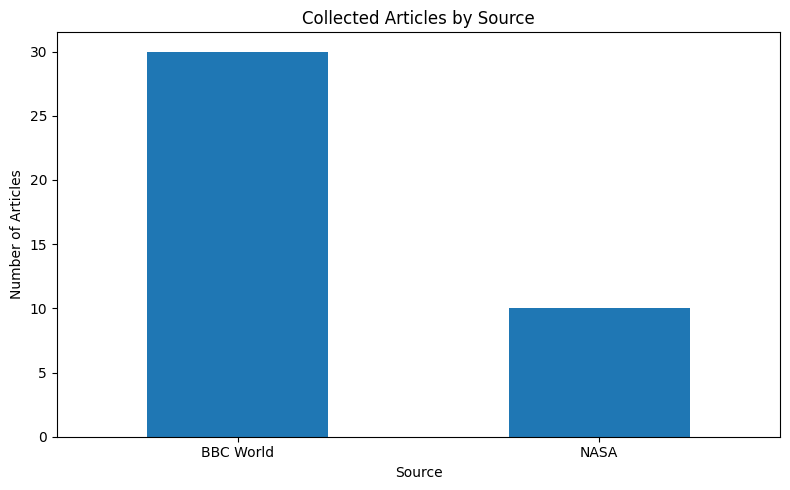

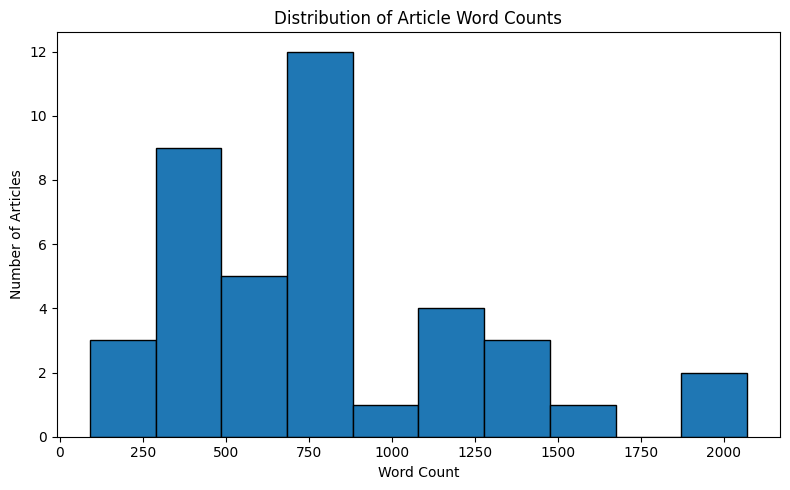

===== LATEST 10 ARTICLES =====


,source,title,word_count,status_code,crawled_at
39,NASA,Power Up: Roll Out Solar Arrays Boost Space St...,425,200,2026-10-16T21:00:45.188200
38,NASA,NASA’s Hubble Spies Spiral’s Edge,416,200,2026-10-16T21:00:42.302587
37,NASA,NASA to Help Unlock Mysteries of Mars’ Moons i...,782,200,2026-10-16T21:00:39.646112
36,NASA,NASA to Conduct Low-Altitude Flights Over Texa...,201,200,2026-10-16T21:00:37.060605
35,NASA,NASA Satellites Observe Historic 2026 El Niño,1365,200,2026-10-16T21:00:34.566797
34,NASA,NASA Names Stephen Cash Marshall Space Flight ...,748,200,2026-10-16T21:00:32.050285
33,NASA,Isaias Dims the Gulf Coast,1354,200,2026-10-16T21:00:29.398518
32,NASA,I Am Artemis: Allison Mjoen,752,200,2026-10-16T21:00:26.839744
31,NASA,Artemis II Heat Shield After Splashdown,90,200,2026-10-16T21:00:24.262696
30,NASA,APOD: 2026 October 16 – Chasing the Internatio...,289,200,2026-10-16T21:00:21.294840



Dashboard charts saved to: /content/drive/MyDrive/DWM_Web_Crawler/dashboard_charts


In [83]:
# ============================================================
# CELL 23: REFRESH DASHBOARD WITH UPDATED DATA
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Reload the latest dataset from disk.
articles_df = pd.read_csv(DATA_FILE)

# Show the updated dashboard metrics.
display(Markdown("# Web Crawler Dashboard"))
display(Markdown(f"""
- **Total articles:** {len(articles_df)}
- **Sources represented:** {articles_df['source'].nunique()}
- **Unique URLs:** {articles_df['url'].nunique()}
- **Duplicate URLs:** {articles_df['url'].duplicated().sum()}
- **Median article length:** {int(articles_df['word_count'].median())} words
"""))

# Create the output folder for dashboard screenshots and charts.
charts_dir = os.path.join(BASE_DIR, "dashboard_charts")
os.makedirs(charts_dir, exist_ok=True)

# Chart 1: Number of collected articles per source.
source_counts = articles_df["source"].value_counts()

plt.figure(figsize=(8, 5))
source_counts.plot(kind="bar")
plt.title("Collected Articles by Source")
plt.xlabel("Source")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    os.path.join(charts_dir, "articles_by_source.png"),
    dpi=150
)
plt.show()

# Chart 2: Distribution of article word counts.
plt.figure(figsize=(8, 5))
articles_df["word_count"].dropna().plot(
    kind="hist",
    bins=10,
    edgecolor="black"
)
plt.title("Distribution of Article Word Counts")
plt.xlabel("Word Count")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.savefig(
    os.path.join(charts_dir, "word_count_distribution.png"),
    dpi=150
)
plt.show()

# Display the latest 10 collected records.
print("===== LATEST 10 ARTICLES =====")
display(
    articles_df[
        ["source", "title", "word_count", "status_code", "crawled_at"]
    ].sort_values("crawled_at", ascending=False).head(10)
)

print("\nDashboard charts saved to:", charts_dir)

In [84]:
# ============================================================
# CELL 24: REGENERATE FINAL PROJECT EVIDENCE ZIP
# ============================================================

import os
import zipfile

# Define the evidence files that should be included.
evidence_files = [
    "articles.csv",
    "crawler.log",
    "crawl_errors.csv",
    "crawl_state.json",
    "change_history.csv",
    "run_history.csv",
    "source_summary.csv",
    "evidence_summary.txt",
    "validation_summary.txt",
]

# Create a fresh ZIP containing files that currently exist.
zip_path = os.path.join(BASE_DIR, "DWM_Crawler_Evidence.zip")
included_files = []
missing_files = []

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in evidence_files:
        file_path = os.path.join(BASE_DIR, filename)

        if os.path.isfile(file_path):
            zip_file.write(file_path, arcname=filename)
            included_files.append(filename)
        else:
            missing_files.append(filename)

    # Include the dashboard charts if they exist.
    charts_dir = os.path.join(BASE_DIR, "dashboard_charts")

    if os.path.isdir(charts_dir):
        for root, _, filenames in os.walk(charts_dir):
            for filename in filenames:
                file_path = os.path.join(root, filename)
                archive_path = os.path.relpath(file_path, BASE_DIR)
                zip_file.write(file_path, arcname=archive_path)
                included_files.append(archive_path)

# Print the final ZIP contents and any missing files.
print("Evidence ZIP regenerated:", zip_path)
print("\nIncluded files:")
for filename in included_files:
    print("✓", filename)

print("\nMissing optional files:")
for filename in missing_files:
    print("-", filename)

print("\nZIP size:", round(os.path.getsize(zip_path) / 1024, 1), "KB")

Evidence ZIP regenerated: /content/drive/MyDrive/DWM_Web_Crawler/DWM_Crawler_Evidence.zip

Included files:
✓ articles.csv
✓ crawler.log
✓ crawl_state.json
✓ change_history.csv
✓ run_history.csv
✓ source_summary.csv
✓ evidence_summary.txt
✓ validation_summary.txt
✓ dashboard_charts/articles_by_source.png
✓ dashboard_charts/word_count_distribution.png

Missing optional files:
- crawl_errors.csv

ZIP size: 125.6 KB


In [85]:
# ============================================================
# CELL 25: FINAL PROJECT FUNCTIONAL CHECKS
# ============================================================

import os
import json
import zipfile
import pandas as pd

# Test 1: Dataset integrity.
df = pd.read_csv(DATA_FILE)

test_results = []

test_results.append({
    "test": "Dataset contains articles",
    "result": len(df) > 0,
    "details": f"{len(df)} articles"
})

test_results.append({
    "test": "Article URLs are unique",
    "result": df["url"].is_unique,
    "details": f"{df['url'].nunique()} unique URLs"
})

test_results.append({
    "test": "Article content hashes are unique",
    "result": df["content_hash"].dropna().is_unique,
    "details": f"{df['content_hash'].dropna().nunique()} unique hashes"
})

test_results.append({
    "test": "All saved articles have HTTP 200 status",
    "result": df["status_code"].eq(200).all(),
    "details": f"{df['status_code'].eq(200).sum()}/{len(df)} returned 200"
})

# Test 2: Incremental state file is valid JSON.
state_path = os.path.join(BASE_DIR, "crawl_state.json")

try:
    with open(state_path, "r", encoding="utf-8") as f:
        state = json.load(f)

    test_results.append({
        "test": "Incremental state file is valid",
        "result": True,
        "details": f"{len(state)} top-level entries"
    })
except Exception as exc:
    test_results.append({
        "test": "Incremental state file is valid",
        "result": False,
        "details": str(exc)
    })

# Test 3: Evidence ZIP exists and can be opened.
zip_path = os.path.join(BASE_DIR, "DWM_Crawler_Evidence.zip")

try:
    with zipfile.ZipFile(zip_path, "r") as zf:
        bad_file = zf.testzip()
        zip_ok = bad_file is None
        zip_details = (
            f"{len(zf.namelist())} files; archive integrity OK"
            if zip_ok else f"Corrupt member: {bad_file}"
        )

    test_results.append({
        "test": "Evidence ZIP integrity",
        "result": zip_ok,
        "details": zip_details
    })
except Exception as exc:
    test_results.append({
        "test": "Evidence ZIP integrity",
        "result": False,
        "details": str(exc)
    })

# Test 4: Both dashboard charts exist.
charts_dir = os.path.join(BASE_DIR, "dashboard_charts")

for chart_name in [
    "articles_by_source.png",
    "word_count_distribution.png"
]:
    chart_path = os.path.join(charts_dir, chart_name)

    test_results.append({
        "test": f"Dashboard chart: {chart_name}",
        "result": os.path.isfile(chart_path),
        "details": "Present" if os.path.isfile(chart_path) else "Missing"
    })

# Display the results.
results_df = pd.DataFrame(test_results)
display(results_df)

passed = int(results_df["result"].sum())
total = len(results_df)

print(f"\nTests passed: {passed}/{total}")
print("All checks passed." if passed == total else "Review failed checks above.")

,test,result,details
0,Dataset contains articles,True,40 articles
1,Article URLs are unique,True,40 unique URLs
2,Article content hashes are unique,True,40 unique hashes
3,All saved articles have HTTP 200 status,True,40/40 returned 200
4,Incremental state file is valid,True,2 top-level entries
5,Evidence ZIP integrity,True,10 files; archive integrity OK
6,Dashboard chart: articles_by_source.png,True,Present
7,Dashboard chart: word_count_distribution.png,True,Present



Tests passed: 8/8
All checks passed.


In [86]:
# Download the final evidence ZIP from Google Drive to your computer.
from google.colab import files
files.download(
    "/content/drive/MyDrive/DWM_Web_Crawler/DWM_Crawler_Evidence.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>